# How did rising interest rates (2021–23) affect house prices across England’s regions?

Between December 2021 and August 2023, the Bank of England raised interest rates from 0.1% to 5%, the fastest rise in decades, making mortgages much more expensive. Using the UK House Price Index (HM Land Registry) and the Bank of England’s Bank Rate history, this project looks at how house prices changed across England’s nine regions and four property types as rates rose. I filtered the data to the nine English regions, matched each month to the Bank Rate in force at the time, and compared the percentage change in prices between December 2021 and August 2023.

In [1]:
import pandas as pd
houses = pd.read_csv("Average-prices-Property-Type-2026-06.csv")

In [2]:
houses.head(10)

,Date,Region_Name,Area_Code,Detached_Average_Price,Detached_Index,Detached_Monthly_Change,Detached_Annual_Change,Semi_Detached_Average_Price,Semi_Detached_Index,Semi_Detached_Monthly_Change,Semi_Detached_Annual_Change,Terraced_Average_Price,Terraced_Index,Terraced_Monthly_Change,Terraced_Annual_Change,Flat_Average_Price,Flat_Index,Flat_Monthly_Change,Flat_Annual_Change
0,1995-01-01,England,E92000001,86969.0,18.6,NaN,NaN,49270.0,17.8,NaN,NaN,38864.0,16.6,NaN,NaN,40489,17.8,NaN,NaN
1,1995-01-01,Wales,W92000004,66840.0,20.9,NaN,NaN,39500.0,19.7,NaN,NaN,30772.0,19.3,NaN,NaN,31323,24.4,NaN,NaN
2,1995-01-01,Inner London,E13000001,239573.0,12.4,NaN,NaN,129730.0,11.5,NaN,NaN,99972.0,11.1,NaN,NaN,77215,13.3,NaN,NaN
3,1995-01-01,Outer London,E13000002,172477.0,15.2,NaN,NaN,96639.0,14.2,NaN,NaN,72755.0,13.6,NaN,NaN,57785,16.5,NaN,NaN
4,1995-01-01,London,E12000007,176754.0,15.0,NaN,NaN,99239.0,13.9,NaN,NaN,80634.0,12.8,NaN,NaN,67007,14.5,NaN,NaN
5,1995-01-01,East of England,E12000006,89883.0,16.9,NaN,NaN,55549.0,15.9,NaN,NaN,44527.0,15.6,NaN,NaN,38120,19.0,NaN,NaN
6,1995-01-01,North West,E12000002,78983.0,22.2,NaN,NaN,43865.0,20.3,NaN,NaN,31093.0,20.0,NaN,NaN,30535,23.1,NaN,NaN
7,1995-01-01,South East,E12000008,118699.0,17.0,NaN,NaN,66595.0,16.0,NaN,NaN,50675.0,15.6,NaN,NaN,41922,18.9,NaN,NaN
8,1995-01-01,West Midlands Region,E12000005,82264.0,20.3,NaN,NaN,45335.0,19.0,NaN,NaN,35428.0,18.5,NaN,NaN,32135,23.2,NaN,NaN
9,1995-01-01,South West,E12000009,90032.0,17.6,NaN,NaN,53406.0,16.5,NaN,NaN,42560.0,16.1,NaN,NaN,35364,19.2,NaN,NaN


In [3]:
houses.shape

(145020, 19)

In [4]:
houses.info()

<class 'pandas.DataFrame'>
RangeIndex: 145020 entries, 0 to 145019
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Date                          145020 non-null  str    
 1   Region_Name                   145020 non-null  str    
 2   Area_Code                     145020 non-null  str    
 3   Detached_Average_Price        144642 non-null  float64
 4   Detached_Index                144642 non-null  float64
 5   Detached_Monthly_Change       144247 non-null  float64
 6   Detached_Annual_Change        139926 non-null  float64
 7   Semi_Detached_Average_Price   144642 non-null  float64
 8   Semi_Detached_Index           144642 non-null  float64
 9   Semi_Detached_Monthly_Change  144247 non-null  float64
 10  Semi_Detached_Annual_Change   139926 non-null  float64
 11  Terraced_Average_Price        144753 non-null  float64
 12  Terraced_Index                144753 non-null  float64


In [5]:
houses["Date"] = pd.to_datetime(houses["Date"])
houses.info()

<class 'pandas.DataFrame'>
RangeIndex: 145020 entries, 0 to 145019
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   Date                          145020 non-null  datetime64[us]
 1   Region_Name                   145020 non-null  str           
 2   Area_Code                     145020 non-null  str           
 3   Detached_Average_Price        144642 non-null  float64       
 4   Detached_Index                144642 non-null  float64       
 5   Detached_Monthly_Change       144247 non-null  float64       
 6   Detached_Annual_Change        139926 non-null  float64       
 7   Semi_Detached_Average_Price   144642 non-null  float64       
 8   Semi_Detached_Index           144642 non-null  float64       
 9   Semi_Detached_Monthly_Change  144247 non-null  float64       
 10  Semi_Detached_Annual_Change   139926 non-null  float64       
 11  Terraced_Average_Price  

The dataset for the UK House Price Index mixed countries, regions and counties so I created a mask to filter a new dataFrame by using the `Area Code` as all the nine English regions start with `E12`

In [6]:
english_region_mask = houses["Area_Code"].str.startswith("E12")
english_houses = houses[english_region_mask]
english_houses.info()
english_prices = english_houses[["Date","Region_Name","Detached_Average_Price","Semi_Detached_Average_Price","Terraced_Average_Price","Flat_Average_Price"]]

<class 'pandas.DataFrame'>
Index: 3402 entries, 4 to 144671
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Date                          3402 non-null   datetime64[us]
 1   Region_Name                   3402 non-null   str           
 2   Area_Code                     3402 non-null   str           
 3   Detached_Average_Price        3402 non-null   float64       
 4   Detached_Index                3402 non-null   float64       
 5   Detached_Monthly_Change       3393 non-null   float64       
 6   Detached_Annual_Change        3294 non-null   float64       
 7   Semi_Detached_Average_Price   3402 non-null   float64       
 8   Semi_Detached_Index           3402 non-null   float64       
 9   Semi_Detached_Monthly_Change  3393 non-null   float64       
 10  Semi_Detached_Annual_Change   3294 non-null   float64       
 11  Terraced_Average_Price        3402 non-null 

In [7]:
english_prices = english_prices.reset_index(drop=True)
english_prices.head()

,Date,Region_Name,Detached_Average_Price,Semi_Detached_Average_Price,Terraced_Average_Price,Flat_Average_Price
0,1995-01-01,London,176754.0,99239.0,80634.0,67007
1,1995-01-01,East of England,89883.0,55549.0,44527.0,38120
2,1995-01-01,North West,78983.0,43865.0,31093.0,30535
3,1995-01-01,South East,118699.0,66595.0,50675.0,41922
4,1995-01-01,West Midlands Region,82264.0,45335.0,35428.0,32135


In [8]:
bank_rate = pd.read_csv("Bank Rate history and data  Bank of England Database.csv")
bank_rate.head()

,Date Changed,Rate
0,18 Dec 25,3.75
1,07 Aug 25,4.00
2,08 May 25,4.25
3,06 Feb 25,4.50
4,07 Nov 24,4.75


In [9]:
bank_rate = bank_rate.rename({"Date Changed":"Date"},axis = 1)
bank_rate.head()

,Date,Rate
0,18 Dec 25,3.75
1,07 Aug 25,4.00
2,08 May 25,4.25
3,06 Feb 25,4.50
4,07 Nov 24,4.75


In [10]:
bank_rate["Date"] = pd.to_datetime(bank_rate["Date"],format ="%d %b %y")
bank_rate.head(), bank_rate["Date"].max(), bank_rate["Date"].min()

(        Date  Rate
 0 2025-12-18  3.75
 1 2025-08-07  4.00
 2 2025-05-08  4.25
 3 2025-02-06  4.50
 4 2024-11-07  4.75,
 Timestamp('2025-12-18 00:00:00'),
 Timestamp('1975-01-20 00:00:00'))

Converted `Date` to the datetime format and only kept the four relevant columns that displayed the average price per property type


In [11]:
bank_rate = bank_rate.sort_values(by="Date")
bank_rate = bank_rate.rename({"Rate":"Bank_Rate"}, axis = 1)
bank_rate

,Date,Bank_Rate
257,1975-01-20,11.25
256,1975-01-27,11.00
255,1975-02-10,10.75
254,1975-02-17,10.50
253,1975-03-10,10.25
...,...,...
4,2024-11-07,4.75
3,2025-02-06,4.50
2,2025-05-08,4.25
1,2025-08-07,4.00


In [12]:
prices_and_rate = pd.merge_asof(english_prices,bank_rate,on="Date")

In [13]:
prices_and_rate["Year"] = prices_and_rate["Date"].dt.year
prices_and_rate

,Date,Region_Name,Detached_Average_Price,Semi_Detached_Average_Price,Terraced_Average_Price,Flat_Average_Price,Bank_Rate,Year
0,1995-01-01,London,176754.0,99239.0,80634.0,67007,6.13,1995
1,1995-01-01,East of England,89883.0,55549.0,44527.0,38120,6.13,1995
2,1995-01-01,North West,78983.0,43865.0,31093.0,30535,6.13,1995
3,1995-01-01,South East,118699.0,66595.0,50675.0,41922,6.13,1995
4,1995-01-01,West Midlands Region,82264.0,45335.0,35428.0,32135,6.13,1995
...,...,...,...,...,...,...,...,...
3397,2026-06-01,East Midlands,355768.0,228937.0,185418.0,123300,3.75,2026
3398,2026-06-01,West Midlands Region,423583.0,254531.0,204871.0,139136,3.75,2026
3399,2026-06-01,East of England,526224.0,352908.0,289513.0,190918,3.75,2026
3400,2026-06-01,London,1162231.0,721916.0,640508.0,431036,3.75,2026


In [14]:
yearly = prices_and_rate.groupby("Year")[["Detached_Average_Price","Semi_Detached_Average_Price","Terraced_Average_Price","Flat_Average_Price","Bank_Rate"]].mean()
yearly


,Detached_Average_Price,Semi_Detached_Average_Price,Terraced_Average_Price,Flat_Average_Price,Bank_Rate
Year,,,,,
1995,93949.370370,54563.990741,42522.333333,37115.509259,6.546667
1996,96293.259259,55512.333333,43114.490741,37448.722222,5.925000
1997,106443.592593,60747.574074,47120.287037,40395.712963,6.454167
1998,116627.351852,66177.212963,51149.990741,44002.500000,7.291667
1999,127310.675926,71981.287037,55814.481481,48537.018519,5.395833
2000,148709.722222,83440.148148,64251.259259,56950.268519,5.937500
2001,165188.620370,92759.277778,71702.814815,64848.611111,5.250000
2002,194793.018519,110764.703704,85651.407407,79070.712963,4.000000
2003,228673.787037,133310.962963,103332.370370,95023.092593,3.708333


In [15]:
yearly = yearly.round({
    "Detached_Average_Price": 0,
    "Semi_Detached_Average_Price": 0,
    "Terraced_Average_Price": 0,
    "Flat_Average_Price": 0,
    "Bank_Rate": 2
})
yearly

,Detached_Average_Price,Semi_Detached_Average_Price,Terraced_Average_Price,Flat_Average_Price,Bank_Rate
Year,,,,,
1995,93949.0,54564.0,42522.0,37116.0,6.55
1996,96293.0,55512.0,43114.0,37449.0,5.92
1997,106444.0,60748.0,47120.0,40396.0,6.45
1998,116627.0,66177.0,51150.0,44002.0,7.29
1999,127311.0,71981.0,55814.0,48537.0,5.40
2000,148710.0,83440.0,64251.0,56950.0,5.94
2001,165189.0,92759.0,71703.0,64849.0,5.25
2002,194793.0,110765.0,85651.0,79071.0,4.00
2003,228674.0,133311.0,103332.0,95023.0,3.71


<Axes: title={'center': 'Bank rate and House price comparison'}, xlabel='Year'>

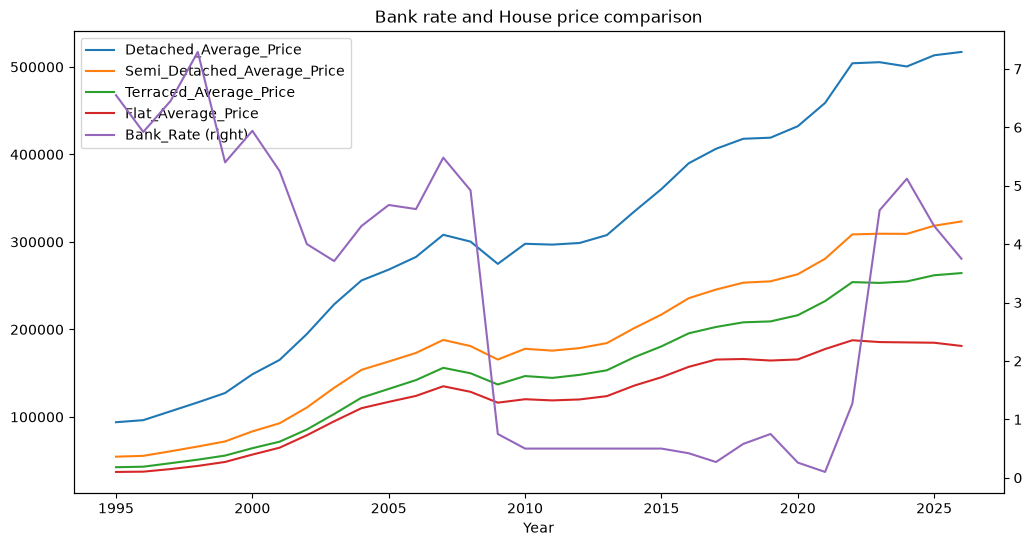

In [16]:
ax = yearly.plot(secondary_y="Bank_Rate", figsize=(12, 6), title="Bank rate and House price comparison")
ax

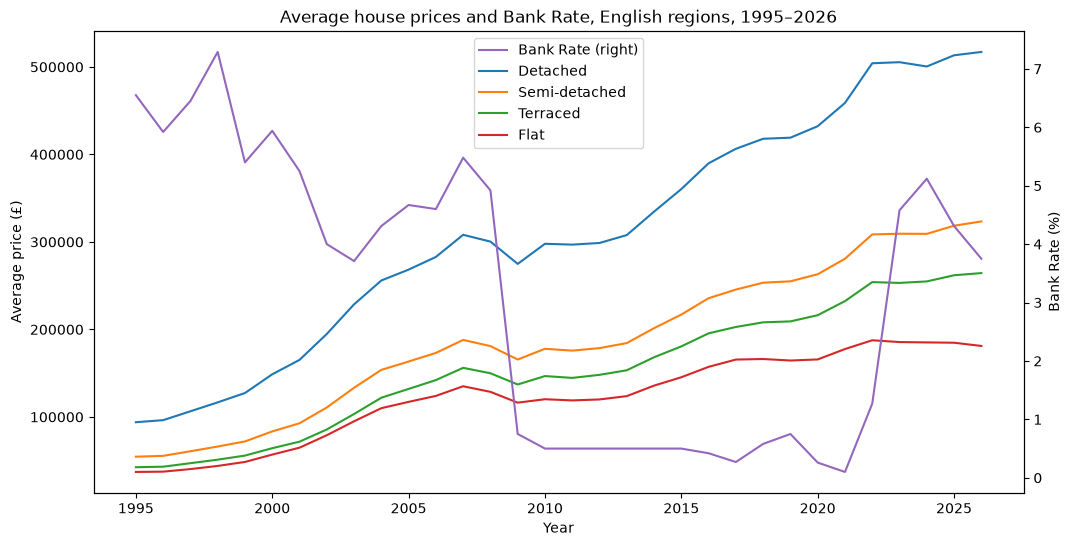

In [17]:
yearly = yearly.rename(columns={
    "Detached_Average_Price": "Detached",
    "Semi_Detached_Average_Price": "Semi-detached",
    "Terraced_Average_Price": "Terraced",
    "Flat_Average_Price": "Flat",
    "Bank_Rate":"Bank Rate"})
ax = yearly.plot(secondary_y="Bank Rate", figsize=(12, 6), title="Average house prices and Bank Rate, English regions, 1995–2026")
right_handles, right_labels = ax.right_ax.get_legend_handles_labels()
left_handles, left_labels = ax.get_legend_handles_labels()
labels = right_labels + left_labels
handles = right_handles + left_handles

ax.set_ylabel("Average price (£)")
ax.right_ax.set_ylabel("Bank Rate (%)")
ax.legend(handles,labels,loc="upper center");

Prices rose steadily during the low-rate years and flattened after 2022 rather than falling, and the 2008 dip was the financial crisis. Detached prices went from around £94K in 1995 to £500K+ in 2025 showing a 5x increase! In 2008, prices dipped while the rate was cut from about 5% to 0.5%. That was the financial crisis: the rate cut was a response to it, not the cause.

In [18]:
date_2021 = prices_and_rate["Date"] == "2021-12-01"
date_2023 = prices_and_rate["Date"] == "2023-08-01"
key_dates = prices_and_rate[date_2021 | date_2023]
key_dates

,Date,Region_Name,Detached_Average_Price,Semi_Detached_Average_Price,Terraced_Average_Price,Flat_Average_Price,Bank_Rate,Year
2907,2021-12-01,East of England,498519.0,324942.0,269217.0,193635,0.1,2021
2908,2021-12-01,North East,248792.0,144782.0,117093.0,93819,0.1,2021
2909,2021-12-01,North West,330758.0,201075.0,147248.0,128498,0.1,2021
2910,2021-12-01,Yorkshire and The Humber,306875.0,182959.0,144554.0,120067,0.1,2021
2911,2021-12-01,East Midlands,327035.0,203704.0,166728.0,121522,0.1,2021
2912,2021-12-01,West Midlands Region,376504.0,219475.0,178624.0,131934,0.1,2021
2913,2021-12-01,London,1110144.0,669304.0,599668.0,451268,0.1,2021
2914,2021-12-01,South East,653791.0,384041.0,303470.0,212824,0.1,2021
2915,2021-12-01,South West,472131.0,294199.0,243878.0,175005,0.1,2021
3087,2023-08-01,West Midlands Region,404492.0,238559.0,193079.0,138080,5.0,2023


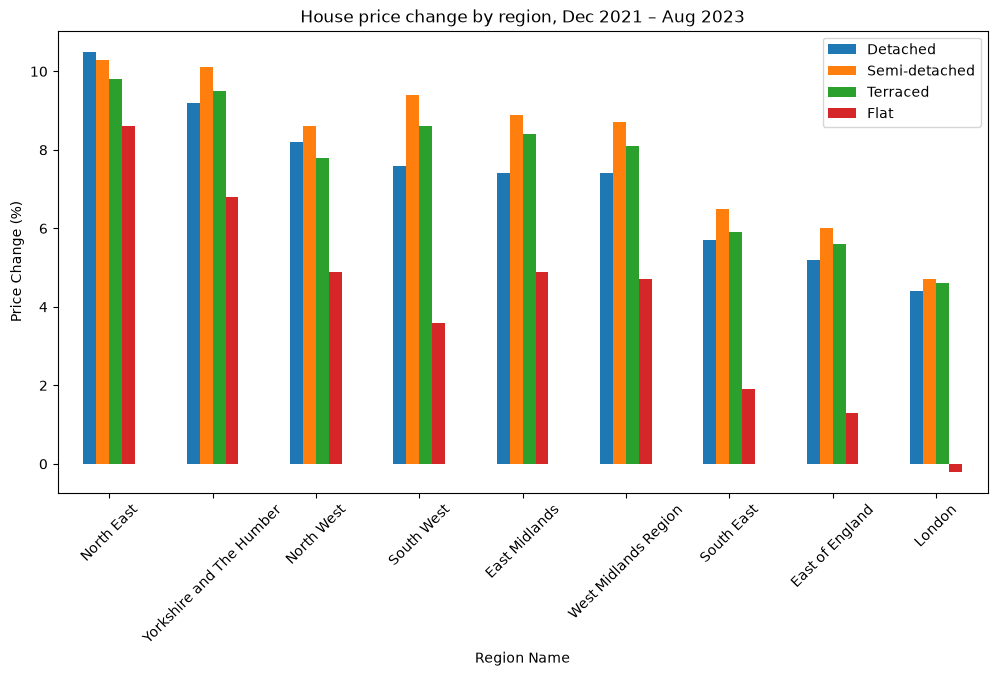

In [19]:
before_mask = key_dates["Date"] == "2021-12-01"
after_mask = key_dates["Date"] == "2023-08-01"
before = key_dates[before_mask]
after = key_dates[after_mask]
before = before.set_index("Region_Name")
after = after.set_index("Region_Name")
after = after[["Detached_Average_Price", "Semi_Detached_Average_Price",
              "Terraced_Average_Price", "Flat_Average_Price"]]
before = before[["Detached_Average_Price", "Semi_Detached_Average_Price",
              "Terraced_Average_Price", "Flat_Average_Price"]]


pct_change = ((after - before) / before * 100).round(1)
pct_change = pct_change.sort_values(by="Detached_Average_Price", ascending = False)
pct_change = pct_change.rename(columns={
    "Detached_Average_Price": "Detached",
    "Semi_Detached_Average_Price": "Semi-detached",
    "Terraced_Average_Price": "Terraced",
    "Flat_Average_Price": "Flat"
})
pct_change.plot(kind="bar",title ="House price change by region, Dec 2021 – Aug 2023", figsize = (12,6), ylabel ="Price Change (%)", xlabel ="Region Name",rot = 45);

Every region increase in prise change between Dec 2021 - Aug 2023 except Flat in London which showed a -0.2% price change. North East showed the biggest price change, 9–10% for houses and 8.6% for flats, and London grew least, under 5%. The more expensive regions being near the bottom of England.


## Conclusion

Between December 2021 and August 2023, the Bank Rate rose from 0.1% to 5%, but house prices did not fall overall. Prices still rose in every region except for London flats (−0.2%). However, growth was uneven: the North East rose the most (8.6–10.5%), while London (−0.2–4.7%), the South East and the East of England rose the least. Flats were the weakest property type in every region.

**Limitations**
- Prices are not adjusted for inflation, which was high over this period, so a rise of 4–5% is likely a fall in real terms.
- The data shows prices and rates changing at the same time, not that the rate rise caused the price changes.
- House prices react slowly because many mortgages are fixed for 2–5 years, so some effects may only show after August 2023.

**Next steps**
Adjust prices for inflation using ONS CPI data to see the real change in each region.
